# 04 · Release years, genres and artists (MusicBrainz)

Questions answered with the MusicBrainz + Wikidata enrichment built by [`enrich.py`](enrich.py):
`data/songs.parquet` (release date, genres) and `data/artists.parquet` (gender, birth date and place).
See the README's **MusicBrainz enrichment** section for how each field is matched and its caveats.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, StrMethodFormatter
from plays import load_plays, load_songs, load_artists

pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE = "#2a78d6"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # categorical slots 1-4, always in this order
LABEL_INK = "#52514e"  # direct labels use text ink, not the series color

plays = load_plays()
music = plays[plays.is_music]
songs = load_songs()
artists = load_artists()

# every music play, with its song's and artist's MusicBrainz facts
p = (
    music[["played_at", "song_key", "artist_key"]]
    .merge(songs[["song_key", "release_date", "release_year", "genres"]], on="song_key", how="left")
    .merge(artists[["artist_key", "type", "gender", "birth_date", "birth_location", "birth_state",
                    "birth_country", "match_method"]], on="artist_key", how="left")
)
p["year"] = p.played_at.dt.year
p["genre"] = p.genres.str.split(", ").str[0].replace("", pd.NA)  # top-voted genre
print(f"{len(p):,} music plays · {len(songs):,} songs · {len(artists):,} artists")
print(f"Plays through {p.played_at.max():%Y-%m-%d}, so {p.year.max()} is a partial year.")


def line_chart(df, title, ylabel, gap_px=13):
    # one line per column (fixed color order), zero baseline, legend + end labels nudged apart
    fig, ax = plt.subplots(figsize=(10, 3.5))
    for (name, ser), c in zip(df.items(), SERIES):
        ax.plot(ser.index, ser, color=c, lw=2, label=name)
    ax.set(title=title, ylabel=ylabel)
    ax.set_ylim(bottom=0)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(fontsize=8, frameon=False, loc="best")
    fig.canvas.draw()
    ends = list((ax.transData.transform((ser.dropna().index[-1], ser.dropna().iloc[-1])), name)
                  for name, ser in df.items())
    ends.sort(key=lambda e: e[0][1])
    last_y = None
    for (x, y), name in ends:
        if last_y is not None and y - last_y < gap_px:
            y = last_y + gap_px
        last_y = y
        ax.annotate(name, ax.transData.inverted().transform((x, y)), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=8, color=LABEL_INK, annotation_clip=False)
    plt.show()

2,472,327 music plays · 93,691 songs · 24,320 artists
Plays through 2026-10-11, so 2026 is a partial year.


## How much of the playlist could be matched?

MusicBrainz facts reach a play only through its album ID, so coverage is measured **by plays**, not by songs:
a long tail of rarely played songs has no ID, but they're a small share of airtime.

In [2]:
def share(mask):
    return f"{mask.mean():.0%}"

has = lambda col: p[col].notna() & (p[col].astype(str) != "")
people = p.type == "Person"
coverage = pd.Series({
    "artist matched to MusicBrainz": share(p.match_method.notna()),
    "song has a release year": share(has("release_year")),
    "song has a genre": share(has("genres")),
    "artist has a birth/formation date": share(has("birth_date")),
    "artist has a birth/formation place": share(has("birth_location")),
    "gender known (solo artists only)": share(has("gender")[people] if people.any() else people),
}, name="share of music plays")
coverage.to_frame()

,share of music plays
artist matched to MusicBrainz,98%
song has a release year,97%
song has a genre,95%
artist has a birth/formation date,93%
artist has a birth/formation place,93%
gender known (solo artists only),99%


In [3]:
# How each station artist was matched (weighted by plays).
# `single_credit` = the album's only credited artist, used even though the name differs. Most are spelling
# variants (BORNS → BØRNS) or full band names, but some are wrong album IDs pointing at another artist's
# record (e.g. The Hollies → Graham Nash). They're ~1% of plays; check any artist you report on.
print(p.match_method.fillna("not matched").value_counts(normalize=True).map("{:.1%}".format).to_string())
check = artists[(artists.match_method == "single_credit")].nlargest(15, "plays")
check[["artist", "mb_name", "plays"]]

match_method
exact            95.9%
not matched       1.7%
contained         1.3%
single_credit     1.0%


,artist,mb_name,plays
208,Jimi Hendrix,The Jimi Hendrix Experience,2552
329,Run DMC,Run‐D.M.C.,1785
432,BORNS,BØRNS,1427
597,Cee Lo,CeeLo Green,995
782,The Go Go's,Go‐Go’s,736
958,Noel Gallagher,Noel Gallagher’s High Flying Birds,560
980,Altin Gun,Altın Gün,545
1198,Sierra Leone's Refugee All-Stars,Sierra Leone’s Refugee All Stars,407
1295,The Hollies,Graham Nash,370
1326,Robyn Hitchcock,Robyn Hitchcock and the Egyptians,356


## How old is the music The Current plays?

**Song age** = year played − original release year. A song played the year it came out has age 0.
The **median** age is 1 year in every year since 2006 (about half of all plays are new releases), so the chart
below tracks the average and the 75th percentile, which show how far back the older half of the playlist reaches.

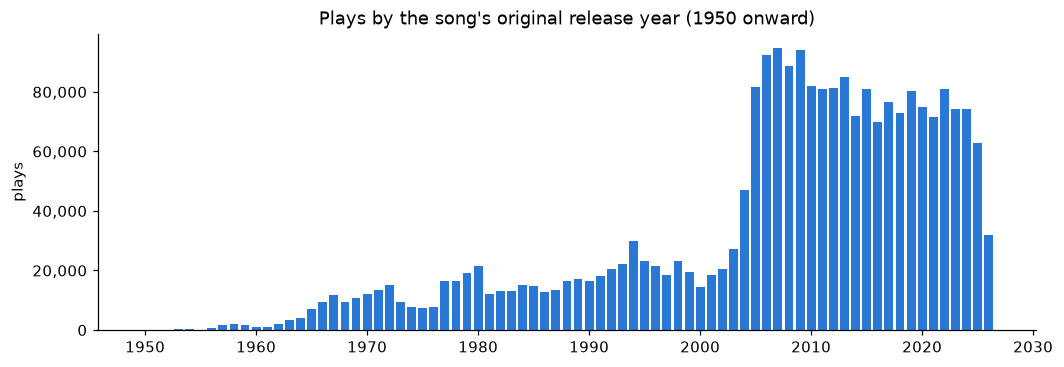

Median song age at airing: 1 years
53% of dated plays were of songs released that year or the year before


In [4]:
dated = p.dropna(subset=["release_year"])
dated = dated[dated.release_year.between(1900, 2030)]
age = (dated.year - dated.release_year).clip(lower=0)

counts = dated.release_year.astype(int).value_counts().sort_index().loc[1950:]
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(counts.index, counts.values, color=BLUE, width=0.8)
ax.set(title="Plays by the song's original release year (1950 onward)", ylabel="plays")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.show()

print(f"Median song age at airing: {age.median():.0f} years")
print(f"{(age <= 1).mean():.0%} of dated plays were of songs released that year or the year before")

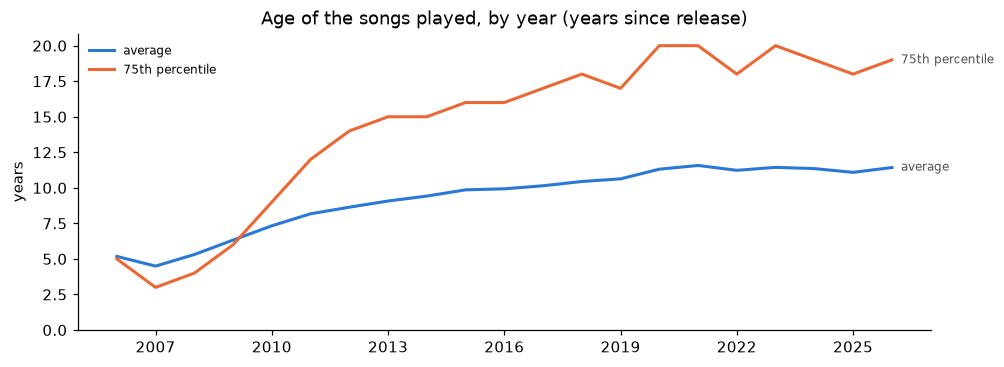

year,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
average,5.2,4.5,5.3,6.3,7.3,8.2,8.6,9.1,9.4,9.9,...,10.1,10.4,10.6,11.3,11.6,11.2,11.4,11.4,11.1,11.4
75th percentile,5.0,3.0,4.0,6.0,9.0,12.0,14.0,15.0,15.0,16.0,...,17.0,18.0,17.0,20.0,20.0,18.0,20.0,19.0,18.0,19.0


In [5]:
by_year = dated.assign(age=age).groupby("year").age
lines = pd.DataFrame({"average": by_year.mean(), "75th percentile": by_year.quantile(0.75)}).loc[2006:]

line_chart(lines, "Age of the songs played, by year (years since release)", "years")
lines.round(1).T

## How much new music does The Current play?

Share of each year's dated plays that went to songs released **that year or the year before**,
compared with songs **20+ years old**.

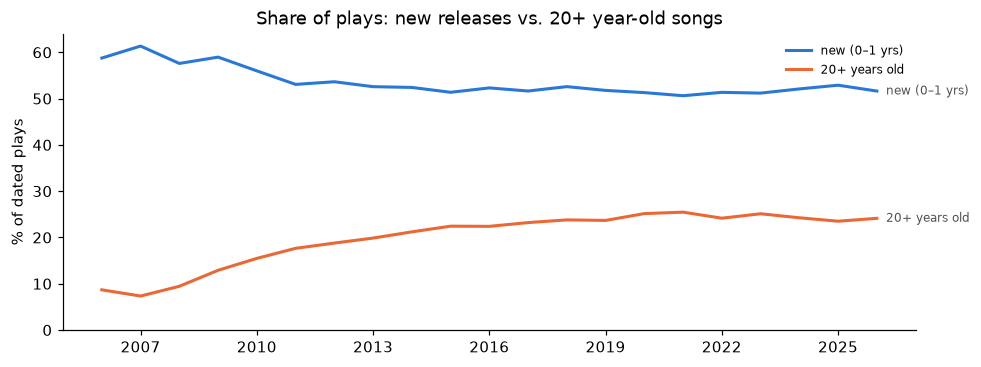

year,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
new (0–1 yrs),59,61,58,59,56,53,54,53,52,51,...,52,53,52,51,51,51,51,52,53,52
20+ years old,9,7,9,13,15,18,19,20,21,22,...,23,24,24,25,25,24,25,24,24,24


In [6]:
mix = pd.DataFrame({
    "new (0–1 yrs)": (age <= 1).groupby(dated.year).mean(),
    "20+ years old": (age >= 20).groupby(dated.year).mean(),
}).loc[2006:] * 100

line_chart(mix, "Share of plays: new releases vs. 20+ year-old songs", "% of dated plays")
mix.round(0).astype(int).T

In [7]:
# Most-played songs released before 1980
old = (songs[songs.release_year < 1980]
       .nlargest(20, "plays")[["title", "artist", "release_year", "release_album", "plays"]])
old

,title,artist,release_year,release_album,plays
151,Lust For Life,Iggy Pop,1977,Lust for Life,478
297,Psycho Killer,Talking Heads,1977,Talking Heads: 77,435
310,Heart Of Glass,Blondie,1978,Parallel Lines,432
378,Roadrunner,The Modern Lovers,1976,The Modern Lovers,416
397,Heroes,David Bowie,1977,“Heroes”,414
476,London Calling,The Clash,1979,London Calling,402
522,"Another Girl, Another Planet",The Only Ones,1978,The Only Ones,396
537,Rock and Roll,The Velvet Underground,1970,Loaded,394
557,See No Evil,Television,1977,Marquee Moon,391
559,Hanging On The Telephone,Blondie,1978,Parallel Lines,390


## What genres does The Current play most?

Each song gets its **top-voted MusicBrainz genre** (from its release album, else from the artist).
Genres are crowd-tagged, so they're broad and occasionally odd; treat them as a rough guide.

95% of plays have a genre · 527 distinct top genres


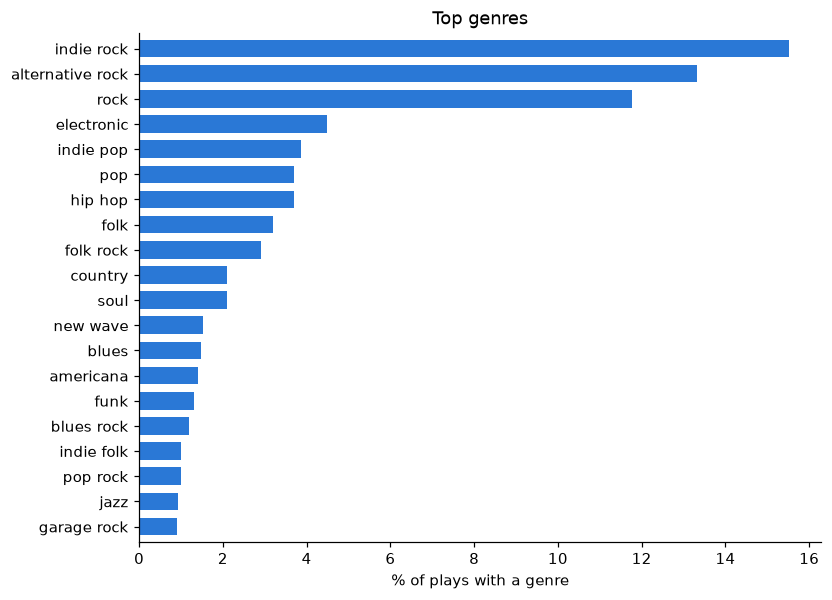

In [8]:
top_genres = p.genre.value_counts()
print(f"{p.genre.notna().mean():.0%} of plays have a genre · {top_genres.size:,} distinct top genres")

top20 = (top_genres.head(20) / top_genres.sum() * 100).iloc[::-1]
ax = top20.plot.barh(color=BLUE, width=0.7, figsize=(8, 6))
ax.set(title="Top genres", xlabel="% of plays with a genre", ylabel="")
plt.show()

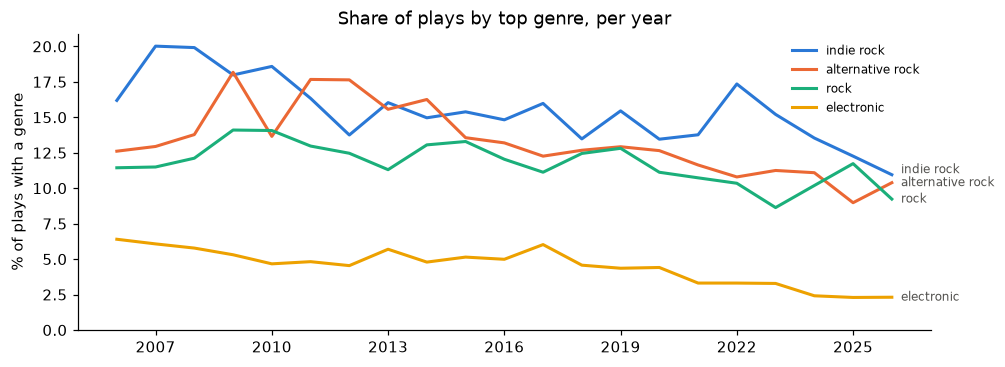

year,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
genre,,,,,,,,,,,,,,,,,,,,,
indie rock,16.2,20.0,19.9,18.0,18.6,16.3,13.8,16.0,15.0,15.4,...,16.0,13.5,15.5,13.5,13.8,17.3,15.2,13.5,12.3,11.0
alternative rock,12.6,12.9,13.8,18.2,13.7,17.7,17.6,15.6,16.3,13.6,...,12.3,12.7,12.9,12.6,11.6,10.8,11.3,11.1,9.0,10.4
rock,11.4,11.5,12.1,14.1,14.1,13.0,12.5,11.3,13.1,13.3,...,11.1,12.5,12.8,11.1,10.7,10.3,8.6,10.2,11.7,9.2
electronic,6.4,6.1,5.8,5.3,4.7,4.8,4.5,5.7,4.8,5.1,...,6.0,4.6,4.4,4.4,3.3,3.3,3.3,2.4,2.3,2.3


In [9]:
# How the four biggest genres' share of plays has moved
big4 = top_genres.head(4).index.tolist()
share_by_year = (pd.crosstab(p.year, p.genre, normalize="index")[big4] * 100).loc[2006:]

line_chart(share_by_year, "Share of plays by top genre, per year", "% of plays with a genre")
share_by_year.round(1).T

In [10]:
# Biggest risers and fallers among genres with real airtime: share in 2006–2010 vs. the last five full years
full = pd.crosstab(p.year, p.genre, normalize="index") * 100
last = full.index[full.index < pd.Timestamp.now().year].max()
early, late = full.loc[2006:2010].mean(), full.loc[last - 4:last].mean()
change = pd.DataFrame({"2006–10 %": early, f"{last-4}–{str(last)[-2:]} %": late, "change (pts)": late - early})
change = change[(change.iloc[:, 0] >= 0.5) | (change.iloc[:, 1] >= 0.5)].round(2)
pd.concat([change.nlargest(10, "change (pts)"), change.nsmallest(10, "change (pts)")])

,2006–10 %,2021–25 %,change (pts)
genre,,,
indie pop,2.36,5.18,2.81
pop,2.95,4.91,1.96
americana,0.41,2.18,1.76
soul,1.33,2.72,1.39
indie folk,0.43,1.64,1.21
alternative pop,0.01,1.21,1.20
contemporary r&b,0.07,1.24,1.16
r&b,0.08,0.96,0.89
dream pop,0.34,0.87,0.53


## Who gets the airtime: men, women or groups?

Solo artists use their MusicBrainz (or Wikidata) **gender**. Groups have no gender, so they're their own category.
Plays by artists without a match or a known type are left out of the shares.

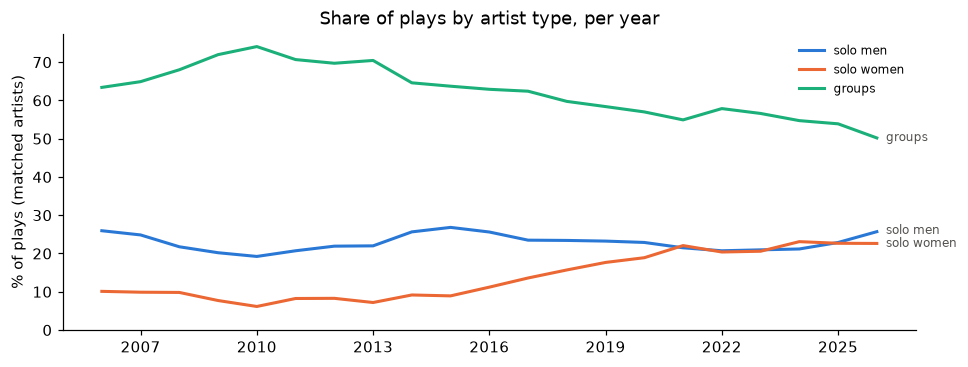

Plays with a known category: 98%


year,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
who,,,,,,,,,,,,,,,,,,,,,
solo men,25.9,24.8,21.8,20.2,19.2,20.7,21.9,22.0,25.6,26.8,...,23.5,23.4,23.2,22.9,21.5,20.7,21.0,21.2,22.9,25.7
solo women,10.1,9.9,9.8,7.7,6.2,8.2,8.3,7.2,9.2,8.9,...,13.6,15.7,17.7,18.9,22.1,20.4,20.6,23.1,22.7,22.6
groups,63.4,64.9,68.0,72.0,74.1,70.7,69.7,70.4,64.6,63.7,...,62.4,59.7,58.4,57.0,54.9,57.9,56.6,54.7,53.9,50.2


In [11]:
def who(row_type, row_gender):
    if row_type == "Person":
        return {"Male": "solo men", "Female": "solo women"}.get(row_gender, "solo, other/unknown gender")
    if row_type in ("Group", "Orchestra", "Choir"):
        return "groups"
    return None

p["who"] = [who(t, g) for t, g in zip(p.type, p.gender)]
order = ["solo men", "solo women", "groups"]
who_year = (pd.crosstab(p.year, p.who, normalize="index")[order] * 100).loc[2006:]

line_chart(who_year, "Share of plays by artist type, per year", "% of plays (matched artists)")

print(f"Plays with a known category: {p.who.notna().mean():.0%}")
who_year.round(1).T

In [12]:
# Most-played solo women
artists[(artists.type == "Person") & (artists.gender == "Female")].head(20)[
    ["artist", "birth_date", "birth_location", "plays", "songs"]]

,artist,birth_date,birth_location,plays,songs
22,St. Vincent,1982-09-28,"Tulsa, Oklahoma, United States",6849,35
33,Courtney Barnett,1987-11-03,"Sydney, New South Wales, Australia",6254,38
36,Brandi Carlile,1981-06-01,"Ravensdale, Washington, United States",6099,102
52,Lizzo,1988-04-27,"Detroit, Michigan, United States",5263,49
56,Lana Del Rey,1985-06-21,"Manhattan, New York, United States",5157,37
64,Dessa,1981-05-23,"Minneapolis, Minnesota, United States",4951,70
70,Feist,1976-02-13,"Amherst, Nova Scotia, Canada",4833,34
76,Neko Case,1970-09-08,"Alexandria, Virginia, United States",4446,63
83,Billie Eilish,2001-12-18,"Los Angeles, California, United States",4361,24
96,Maggie Rogers,1994-04-25,"Easton, Maryland, United States",4078,18


## How much airtime goes to Minnesota artists?

An artist counts as Minnesotan if MusicBrainz/Wikidata says they were **born or formed** in Minnesota.
That misses transplants (e.g. an act that moved to Minneapolis after forming elsewhere), so it's a floor.

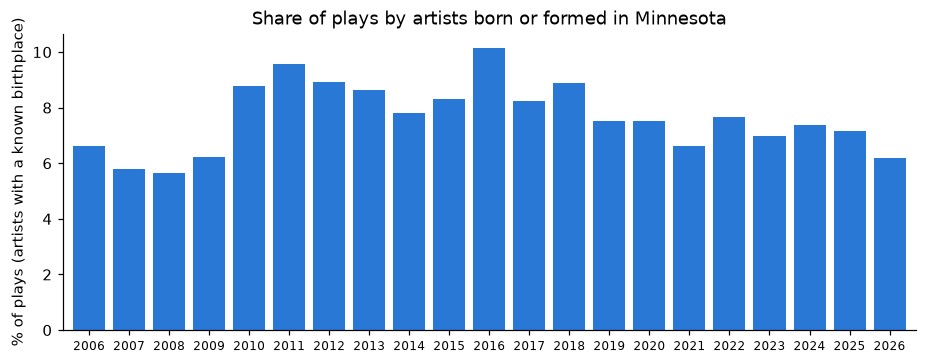

Overall: 7.7% of plays with a known birthplace


,artist,type,birth_location,birth_date,plays
0,Prince,Person,"Minneapolis, Minnesota, United States",1958-06-07,12620
10,Atmosphere,Group,"Minneapolis, Minnesota, United States",1994,7767
17,The Replacements,Group,"Minneapolis, Minnesota, United States",1979,7053
18,Bob Dylan,Person,"Duluth, Minnesota, United States",1941-05-24,7010
23,Cloud Cult,Group,"Minneapolis, Minnesota, United States",1995,6795
49,Trampled By Turtles,Group,"Duluth, Minnesota, United States",2004,5457
50,Hippo Campus,Group,"Minneapolis, Minnesota, United States",2013,5380
53,Low,Group,"Duluth, Minnesota, United States",1993,5215
54,Polica,Group,"Minneapolis, Minnesota, United States",2011,5180
57,The Jayhawks,Group,"Minneapolis, Minnesota, United States",1985,5150


In [13]:
mn = p.birth_state == "Minnesota"
known_place = has("birth_location")
mn_share = (mn[known_place].groupby(p.year[known_place]).mean() * 100).loc[2006:]

ax = mn_share.plot.bar(color=BLUE, width=0.8, figsize=(10, 3.5))
ax.set(title="Share of plays by artists born or formed in Minnesota",
       xlabel="", ylabel="% of plays (artists with a known birthplace)")
ax.tick_params(axis="x", rotation=0, labelsize=8)
plt.show()

print(f"Overall: {mn[known_place].mean():.1%} of plays with a known birthplace")
artists[artists.birth_state == "Minnesota"].head(25)[["artist", "type", "birth_location", "birth_date", "plays"]]

## Where else are the artists from?

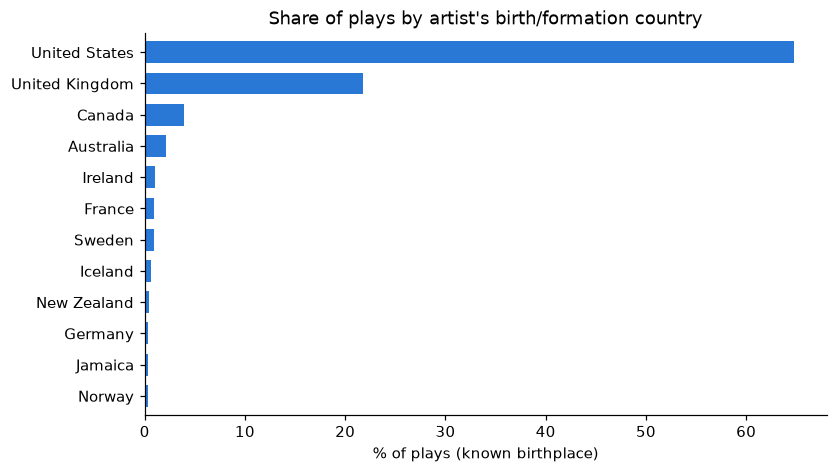

In [14]:
by_country = (p[known_place].birth_country.replace("", pd.NA).value_counts(normalize=True) * 100).head(12)
ax = by_country.iloc[::-1].plot.barh(color=BLUE, width=0.7, figsize=(8, 4.5))
ax.set(title="Share of plays by artist's birth/formation country", xlabel="% of plays (known birthplace)", ylabel="")
plt.show()

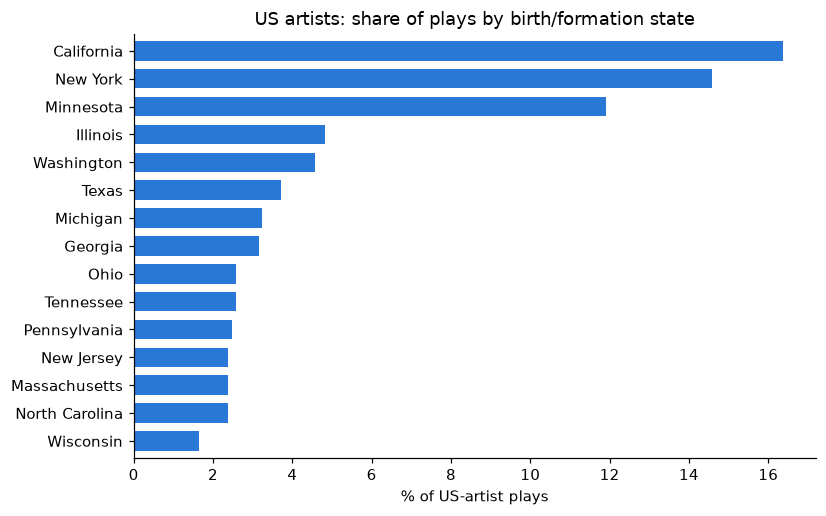

In [15]:
us = p[known_place & (p.birth_country == "United States")]
by_state = (us.birth_state.replace("", pd.NA).value_counts(normalize=True) * 100).head(15)
ax = by_state.iloc[::-1].plot.barh(color=BLUE, width=0.7, figsize=(8, 5))
ax.set(title="US artists: share of plays by birth/formation state", xlabel="% of US-artist plays", ylabel="")
plt.show()

## How old are the artists?

For solo artists with a full birth date: their **age on the day a song of theirs was played**.

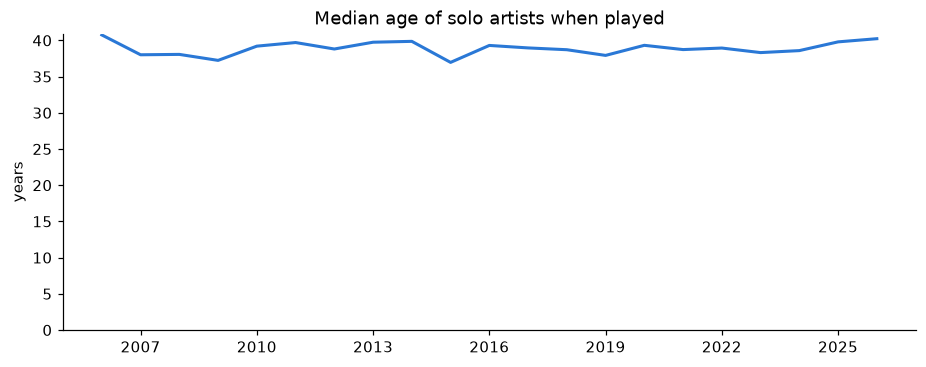

Solo-artist plays with a full birth date: 89%


In [16]:
born = pd.to_datetime(p.birth_date.where(people & (p.birth_date.str.len() == 10)), errors="coerce")
age_at_play = ((p.played_at.dt.tz_localize(None) - born).dt.days / 365.25).where(born.notna())
yearly = age_at_play.groupby(p.year).median().loc[2006:]

ax = yearly.plot(color=BLUE, lw=2, figsize=(10, 3.5))
ax.set(title="Median age of solo artists when played", xlabel="", ylabel="years")
ax.set_ylim(bottom=0)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.show()
print(f"Solo-artist plays with a full birth date: {age_at_play.notna().sum() / people.sum():.0%}")

## Data checks

Songs whose release album's MusicBrainz title doesn't match the station's album name. Usually this is harmless
(a single vs. the album it's from), but it can also flag a wrong album ID. Spot-check the most-played ones.

In [17]:
mismatch = songs[songs.release_album_matches == False]  # noqa: E712 (nullable boolean)
print(f"{len(mismatch):,} songs ({mismatch.plays.sum() / songs.plays.sum():.0%} of plays) have a title mismatch")
mismatch.head(20)[["title", "artist", "release_album", "release_album_type", "release_date", "plays"]]

11,533 songs (10% of plays) have a title mismatch


,title,artist,release_album,release_album_type,release_date,plays
97,Left Hand Free,Alt-J,"This Is All Yours, Too",EP + Compilation,2015-03-12,495
122,Lost in My Mind,The Head and the Heart,KFOG: Live From the Archives 18,Album + Compilation + Live,2011,485
129,After You,Chastity Brown,Back-Road Highways,Album,2012-03-24,484
134,Lights Out,Santigold,I Believe in Santogold EP,EP,2007,482
138,Towers,Bon Iver,"Bon Iver, Bon Iver",Album,2011-06-20,482
159,You'll Be Bright,Cloud Cult,2020 Light Chasers Anniversary Concert,Album + Live,2021-01-22,473
171,Terrible Love,The National,Castle Rock Session,EP + Live,2010,470
180,Just Ain't Gonna Work Out,Mayer Hawthorne,A Strange Arrangement,Album,2009-09-07,467
190,Calgary,Bon Iver,"Bon Iver, Bon Iver",Album,2011-06-20,463
215,Back In Your Head,Tegan and Sara,The Con Demos,Album + Demo,2008,457
